# Part 1 : Ordinary Least Squares OLS (Fake Data)
Simple Linear Regression Idea


In [29]:
import numpy as np
import matplotlib.pyplot as plt


In [30]:
x = np.random.rand(20,1)*10 # feature
x

array([[3.11711076],
       [5.20068021],
       [5.46710279],
       [1.84854456],
       [9.69584628],
       [7.75132823],
       [9.39498942],
       [8.9482735 ],
       [5.97899979],
       [9.21874235],
       [0.88492502],
       [1.95982862],
       [0.45227289],
       [3.25330331],
       [3.8867729 ],
       [2.71349032],
       [8.28737509],
       [3.56753327],
       [2.8093451 ],
       [5.42696083]])

In [31]:
y = 3.5 * x.flatten() + 7 + np.random.randn(20)*3   # target
#y =  m * x            + b
# m= 3.5
# b= 7

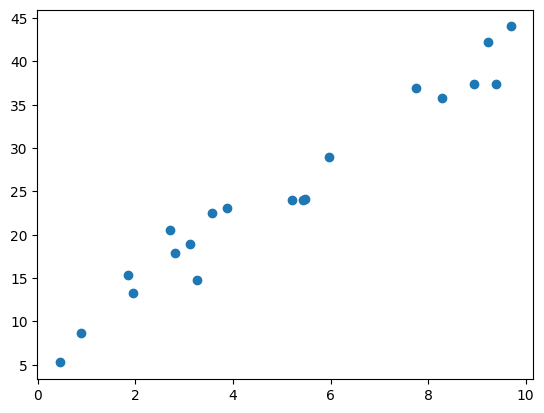

In [32]:
plt.scatter(x,y)
plt.show()

In [33]:
from sklearn.linear_model import LinearRegression

ols_model = LinearRegression()
ols_model.fit(x,y) # >> output >> y with coff (m,b)

LinearRegression()

In [34]:
print("m: ",ols_model.coef_[0])
print("b:",ols_model.intercept_)

m:  3.621327326411669
b: 6.670768535058286


In [35]:
y_prad = ols_model.predict(x) # y^

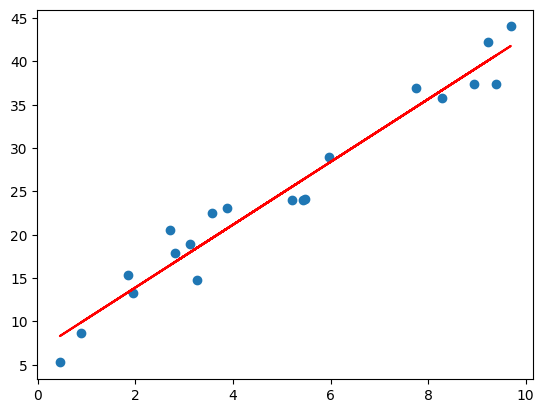

In [36]:
plt.scatter(x,y)
plt.plot(x,y_prad,color="red")
plt.show()

# Part 2 : Ordinary Least Squares OLS (Real Data)
Simple Linear Regression Idea


In [37]:
import seaborn as sns

In [38]:
df = sns.load_dataset("tips")

In [39]:
df

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


In [40]:
df2 = df[["total_bill","tip"]]

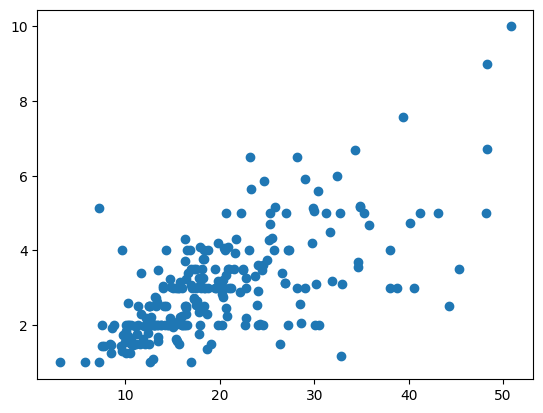

In [41]:
plt.scatter(df2["total_bill"],df2["tip"])
plt.show()

In [42]:
from sklearn.model_selection import train_test_split
train_df, test_df= train_test_split(df2,test_size=0.3,random_state=101)

In [43]:
x_train = train_df[['total_bill']] # X as 2D
y_train = train_df["tip"] # 1D


In [44]:
ols_model_tips = LinearRegression()
ols_model_tips.fit(x_train,y_train)

LinearRegression()

In [45]:
y_pred_train = ols_model_tips.predict(x_train)

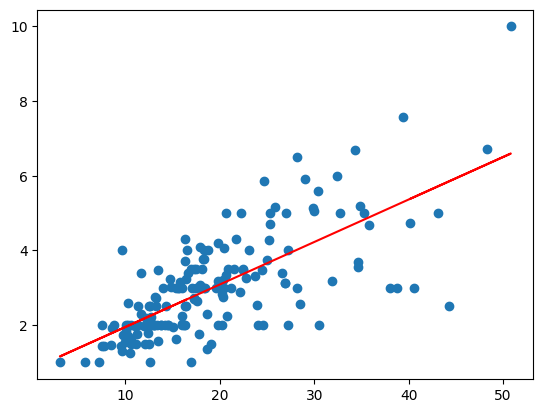

In [46]:
plt.scatter(train_df['total_bill'],train_df["tip"])
plt.plot(x_train,y_pred_train,color="red")
plt.show()

In [47]:
# test_df

test_df["total_bill"]
y_test_pred = ols_model_tips.predict(test_df[["total_bill"]])

In [48]:
y_test_pred- test_df["tip"]

,tip
151,0.306360
34,-0.434202
109,-1.559288
4,0.001169
114,-0.261310
...,...
54,-0.618389
66,0.214368
176,0.848323
134,-0.359550


In [49]:
test_df["tip pred"] = y_test_pred

In [50]:
test_df["diff tip,TipPred"] = test_df["tip"] - test_df["tip pred"]

In [51]:
test_df

,total_bill,tip,tip pred,"diff tip,TipPred"
151,13.13,2.00,2.306360,-0.306360
34,17.78,3.27,2.835798,0.434202
109,14.31,4.00,2.440712,1.559288
4,24.59,3.61,3.611169,-0.001169
114,25.71,4.00,3.738690,0.261310
...,...,...,...,...
54,25.56,4.34,3.721611,0.618389
66,16.45,2.47,2.684368,-0.214368
176,17.89,2.00,2.848323,-0.848323
134,18.26,3.25,2.890450,0.359550


In [52]:
# mean of diff
test_df["diff tip,TipPred"].abs().mean()

np.float64(0.8264143585080423)

# Part 3 : Task (mpg Data)

In [53]:
df = sns.load_dataset("mpg") # mpg : Fuel con.
df

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino
...,...,...,...,...,...,...,...,...,...
393,27.0,4,140.0,86.0,2790,15.6,82,usa,ford mustang gl
394,44.0,4,97.0,52.0,2130,24.6,82,europe,vw pickup
395,32.0,4,135.0,84.0,2295,11.6,82,usa,dodge rampage
396,28.0,4,120.0,79.0,2625,18.6,82,usa,ford ranger


### Input / X: horsepower
### Target / y: mpg

## 8:40 to 9:30 PM >>> Task
## 9:30 to 10:00 >> Q&A about Dataset and model

In [54]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LinearRegression

In [55]:
# 1. Generate Synthetic Data
np.random.seed(42)  # Optional seed for reproducibility
x = np.random.rand(20, 1) * 10
y = 3.5 * x.flatten() + 7 + np.random.randn(20) * 3

In [56]:
# 2. Instantiate and Fit OLS Model
ols_model = LinearRegression()
ols_model.fit(x, y)

LinearRegression()

In [58]:
# 3. Extract Parameters
m = ols_model.coef_[0]
b = ols_model.intercept_

print(f"Fitted Slope (m): {m:.8f}")
print(f"Fitted Intercept (b): {b:.8f}")

Fitted Slope (m): 3.34503958
Fitted Intercept (b): 6.89081501


In [59]:
# 4. Predict and Plot
y_pred = ols_model.predict(x)

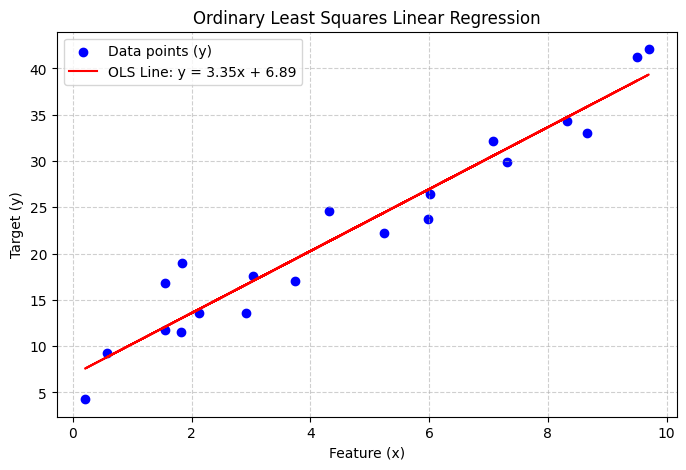

In [60]:
plt.figure(figsize=(8, 5))
plt.scatter(x, y, color="blue", label="Data points (y)")
plt.plot(x, y_pred, color="red", label=f"OLS Line: y = {m:.2f}x + {b:.2f}")
plt.xlabel("Feature (x)")
plt.ylabel("Target (y)")
plt.title("Ordinary Least Squares Linear Regression")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()